## Comparison: nonradiative rate, e-ph spectral density, and lineshape function
### computed at the ${}^3\!E$-relaxed vs. ${}^3\!A_2$-relaxed reference geometry


In [1]:
%matplotlib widget
import os, sys
sys.path.append('/home/svillani/Programs/pypl/pypl/')
import hr_nonrad_solver
from hr_nonrad_solver import hr_nonrad_solver
from utils import *

import numpy as np
from scipy import constants
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'

eV = constants.eV
amu = constants.physical_constants['atomic mass constant'][0]
hbar = constants.hbar
ry2eV = 13.6057039763
bohr2ang = 0.529177249
mass_list = {'C': 12.0107, 'N': 14.0067}

def parse_forces_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    forces = np.array(data['output']['forces']['forces_corrected']).reshape(-1, 3)
    # Ry/bohr to eV/Angstrom
    forces *= (ry2eV / bohr2ang)
    return forces

def parse_nac_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec']['genac_corrected']).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

### Configuration

Both geometries share the same electronic energies (the vertical/adiabatic gaps are fixed properties of the two minima, independent of which geometry's phonons/forces are used to build the lineshape) and the same temperature grid / broadening. What differs is the phonon mesh and the forces/NACs, which are each evaluated at their own relaxed geometry.

In [2]:
# Electronic energies (Rydberg -> eV) -- these differ between the two reference
# geometries, since the vertical TDDFT gap changes with geometry. The 3A2 (GS)
# state energy is 0 by definition for both geometries.
state_3A2_energy_pbe = 0.0
state_3A2_energy_ddh = 0.0

adiabatic_energy_pbe = 1894      # meV
adiabatic_energy_ddh = 2112      # meV
adiabatic_energy = 1945          # meV, experimental

# Temperature grid / broadening for the Gamma_NR(T) panels
temperatures = [0.0, 50, 100, 150, 200, 250, 300, 350, 400]
zpl_broadenings = np.ones_like(temperatures) * (4.13e-4 * 0.5)  # meV (~100 MHz)
zpl_broadening_78K = 4.13e-4 * 0.5                              # meV (~100 MHz)

geometries = {
    '3Egeo': dict(
        title=r'Computed @ ${}^3\;\mathrm{E}$ relaxed geo',
        phonon_file='pbe/3E_ph_mesh.hdf5',
        nac_file_pbe='pbe/3E/west.wbse.save/wbse.json',
        pwscf_file_pbe='pbe/3E/pwscf.xml',
        nac_file_ddh='ddh/3E/west.wbse.save/wbse.json',
        pwscf_file_ddh='ddh/3E/pwscf.xml',
        state_3E_energy_pbe=0.12761 * ry2eV,   # at ES-geo (3E-relaxed)
        state_3E_energy_ddh=0.13946 * ry2eV,   # at ES-geo (3E-relaxed)
    ),
    '3A2geo': dict(
        title=r'Computed @ ${}^3\;\mathrm{A}_2$ relaxed geo',
        phonon_file='pbe/3A2_ph_mesh.hdf5',
        nac_file_pbe='pbe/3E/west.wbse.save/wbse_1.json',
        pwscf_file_pbe='pbe/3E/pwscf_1.xml',
        nac_file_ddh='ddh/3E/west.wbse.save/wbse_1.json',
        pwscf_file_ddh='ddh/3E/pwscf_1.xml',
        state_3E_energy_pbe=0.15259 * ry2eV,   # at GS-geo (3A2-relaxed)
        state_3E_energy_ddh=0.174001 * ry2eV,  # at GS-geo (3A2-relaxed)
    ),
}

### Pipeline

Runs the full HRF / e-ph coupling / lineshape calculation for one reference geometry, for both PBE and DDH.

In [3]:
def run_pipeline(geo):
    """Compute HRFs, e-ph spectral density, Gamma_NR(T), and F_NR at 78 K
    for one reference geometry, for both PBE and DDH levels of theory."""

    phonon_freqs, phonon_modes = parse_phonopy_h5(geo['phonon_file'])

    results = {}
    for level, energy_es, energy_gs, nac_file, pwscf_file, adiabatic_energy_level in [
        ('pbe', geo['state_3E_energy_pbe'], state_3A2_energy_pbe, geo['nac_file_pbe'], geo['pwscf_file_pbe'], adiabatic_energy_pbe),
        ('ddh', geo['state_3E_energy_ddh'], state_3A2_energy_ddh, geo['nac_file_ddh'], geo['pwscf_file_ddh'], adiabatic_energy_ddh),
    ]:
        nac_vec = parse_nac_from_wbse_json(nac_file)
        atomic_symbols, dft_forces = parse_forces_qexml(pwscf_file)

        solver = hr_nonrad_solver()
        d = solver.compute_hrf_forces(phonon_freqs, phonon_modes, atomic_symbols, dft_forces, mass_list=mass_list)
        d = solver.compute_dH_dq(phonon_freqs, phonon_modes, atomic_symbols, nac_vec, energy_es - energy_gs, d, mass_list=mass_list)

        spectral_density = solver.compute_dH_dq_spectral_density(d, energy_axis=np.linspace(-100, 500, 601), sigma=[6, 3])

        # Gamma_NR(T)
        rate_non_rad = []
        for temp, zpl_broadening in zip(temperatures, zpl_broadenings):
            E, F = solver.compute_nonrad_lineshape_fft(
                d, temp=temp, sigma=[6, 2], zpl_broadening=zpl_broadening,
                lineshape_energy_range=[-2400, 2400], lineshape_energy_resolution=48001
            )
            idx = np.argmin(np.abs(E - adiabatic_energy_level))
            rate_non_rad.append(F[idx] * 2 * np.pi / hbar)
        rate_non_rad = np.array(rate_non_rad)

        # F_NR(Delta) at T = 78 K
        F_78K = solver.compute_nonrad_lineshape_fft(
            d, temp=78, sigma=[6, 2], zpl_broadening=zpl_broadening_78K,
            lineshape_energy_range=[-2400, 2400], lineshape_energy_resolution=48001
        )

        results[level] = dict(
            spectral_density=spectral_density,
            rate_non_rad=rate_non_rad,
            F_78K=F_78K,
            adiabatic_energy=adiabatic_energy_level,
        )

    results['title'] = geo['title']
    return results

all_results = {name: run_pipeline(geo) for name, geo in geometries.items()}

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  5.583568696254e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  2.377536857657e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  2.183444758003e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  5.553366854968e-01 (eV/amu^{1/2}/\AA)

time_axis range: -2.0678338484709037e-11 to 2.0678338484709037e-11
d_t (s): 8.615794872902247e-16


/home/svillani/Programs/pypl/pypl/lineshape.py:328: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -2399.9999999895845 to 2399.9999999895845
d_E (meV): 0.09999999999990905
Integral check: 8.775784640289108e-19
time_axis range: -2.0678338484709037e-11 to 2.0678338484709037e-11
d_t (s): 8.615794872902247e-16
Energy range (meV): -2399.9999999895845 to 2399.9999999895845
d_E (meV): 0.09999999999990905
Integral check: 8.77579299962581e-19
time_axis range: -2.0678338484709037e-11 to 2.0678338484709037e-11
d_t (s): 8.615794872902247e-16
Energy range (meV): -2399.9999999895845 to 2399.9999999895845
d_E (meV): 0.09999999999990905
Integral check: 8.779913380127238e-19
time_axis range: -2.0678338484709037e-11 to 2.0678338484709037e-11
d_t (s): 8.615794872902247e-16
Energy range (meV): -2399.9999999895845 to 2399.9999999895845
d_E (meV): 0.09999999999990905
Integral check: 8.814352168587868e-19
time_axis range: -2.0678338484709037e-11 to 2.0678338484709037e-11
d_t (s): 8.615794872902247e-16
Energy range (meV): -2399.9999999895845 to 2399.9999999895845
d_E (meV): 0.0999999999

### Figure

<>:14: SyntaxWarning: invalid escape sequence '\G'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\G'
<>:47: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_851524/866170024.py:14: SyntaxWarning: invalid escape sequence '\G'
  ax[0, col].set_ylabel('$\Gamma_\mathrm{NR}$ (MHz)')
/tmp/ipykernel_851524/866170024.py:47: SyntaxWarning: invalid escape sequence '\m'
  ax[2, col].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')


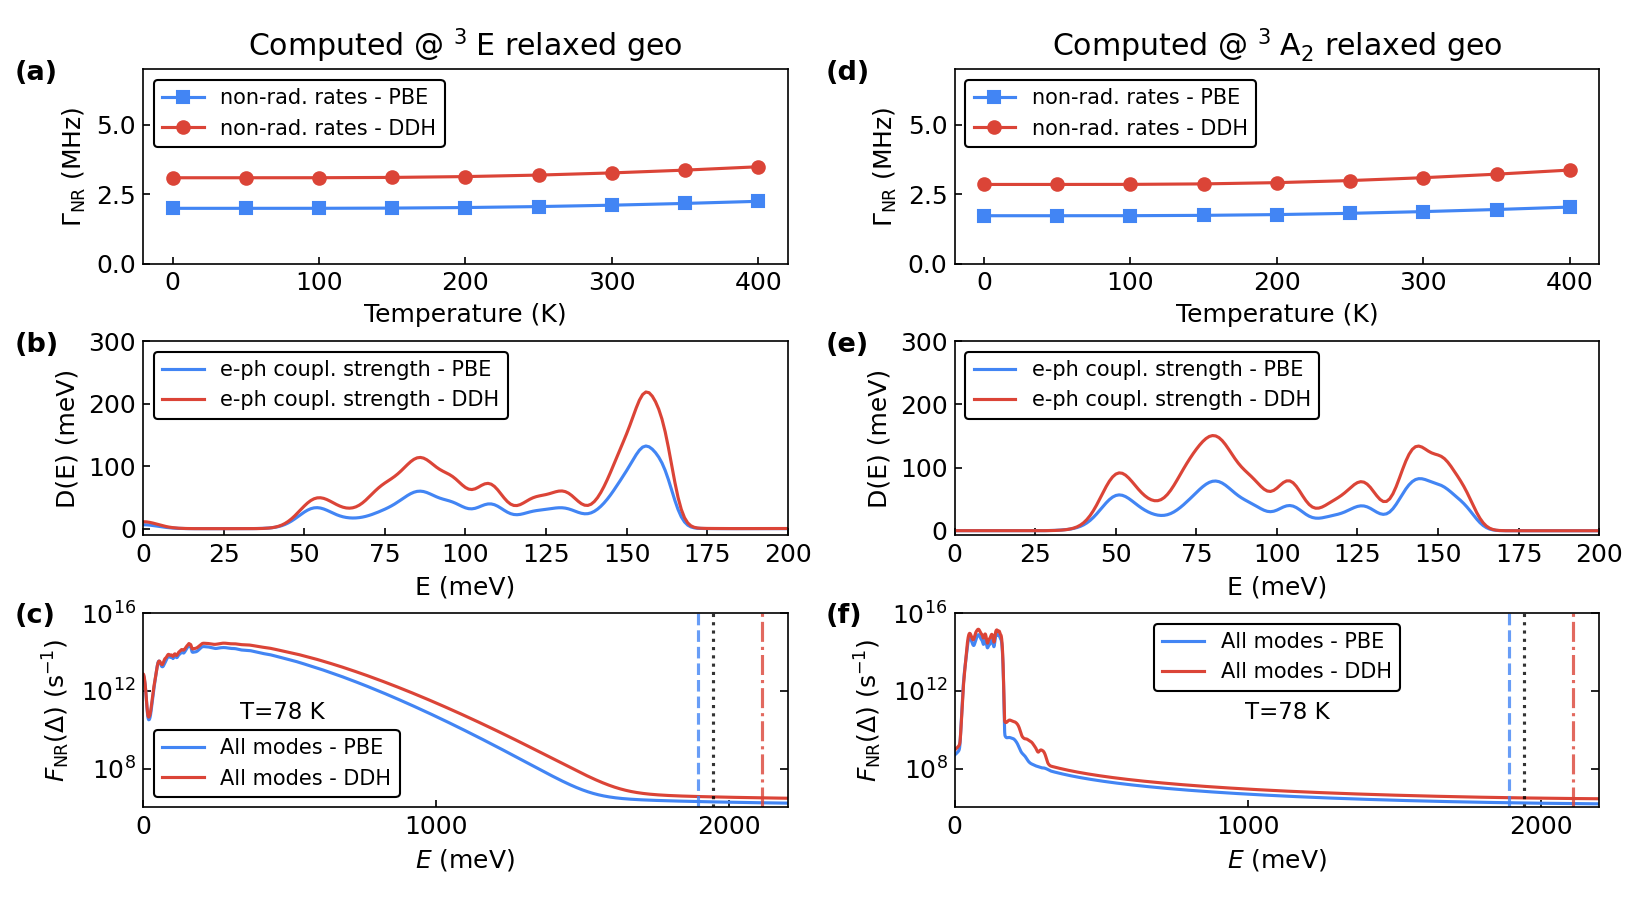

In [4]:
# import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
# -----------------------------
fig, ax = plt.subplots(3, 2, figsize=(11, 6), dpi=150)
# -----------------------------
for col, geo_name in enumerate(['3Egeo', '3A2geo']):
    res = all_results[geo_name]
    pbe, ddh = res['pbe'], res['ddh']

    ax[0, col].plot(temperatures, pbe['rate_non_rad']*1e-6, c=blue, marker='s', label='non-rad. rates - PBE')
    ax[0, col].plot(temperatures, ddh['rate_non_rad']*1e-6, c=red, marker='o', label='non-rad. rates - DDH')
    ax[0, col].set_xlabel('Temperature (K)')
    ax[0, col].set_ylabel('$\Gamma_\mathrm{NR}$ (MHz)')
    ax[0, col].set_ylim(ymin=0, ymax=7)
    ax[0, col].tick_params(direction='in')
    ax[0, col].legend(fontsize=10, edgecolor='k', framealpha=1.0, loc='upper left')
    ax[0, col].set_title(res['title'])
    #
    ax[1, col].plot(pbe['spectral_density'][0], pbe['spectral_density'][1],
            color=blue, ls='-', label='e-ph coupl. strength - PBE')
    ax[1, col].plot(ddh['spectral_density'][0], ddh['spectral_density'][1],
            color=red, ls='-', label='e-ph coupl. strength - DDH')
    ax[1, col].set_xlabel('E (meV)')
    ax[1, col].set_ylabel('D(E) (meV)')
    ax[1, col].tick_params(direction='in')
    ax[1, col].set_yticks([0.0, 100, 200, 300])
    ax[1, col].set_xlim([0, 200])
    ax[1, col].set_ylim(ymax=300)
    ax[1, col].legend(fontsize=10, edgecolor='k', framealpha=1.0, loc='upper left')
    #
    ax[2, col].plot(pbe['F_78K'][0], pbe['F_78K'][1]*2*np.pi/hbar, color=blue, linestyle='-', label='All modes - PBE')
    ax[2, col].plot(ddh['F_78K'][0], ddh['F_78K'][1]*2*np.pi/hbar, color=red, linestyle='-', label='All modes - DDH')
    ax[2, col].set_yscale('log')
    ax[2, col].set_ylim(bottom=1e6, top=1e16)
    ax[2, col].yaxis.set_major_locator(LogLocator(base=10.0, numticks=10))
    ax[2, col].yaxis.set_minor_locator(
        LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)
    )
    ax[2, col].yaxis.set_minor_formatter(NullFormatter())
    ax[2, col].tick_params(axis='y', which='major', direction='in', length=4, right=True)
    ax[2, col].tick_params(axis='y', which='minor', direction='in', length=2, right=True)
    ax[2, col].tick_params(axis='x', which='major', direction='in', top=False)
    ax[2, col].yaxis.set_ticks_position('both')
    ax[2, col].set_yticks([1e8, 1e12, 1e16])
    ax[2, col].set_xlabel('$E$ (meV)')
    ax[2, col].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
    ax[2, col].tick_params(axis='x', which='both', direction='in')
    if col==0: ax[2, col].text(0.15, 0.55, 'T=78 K', transform=ax[2, col].transAxes, ha='left', va='top', fontsize=11)
    if col==1: ax[2, col].text(0.45, 0.55, 'T=78 K', transform=ax[2, col].transAxes, ha='left', va='top', fontsize=11)
    ax[2, col].legend(fontsize=10, edgecolor='k', framealpha=1.0, loc='best')
    ax[2, col].set_xlim([-0, 2200])
    ax[2, col].set_xticks([0, 1000, 2000])
    ax[2, col].axvline(x=pbe['adiabatic_energy'], color=blue, alpha=0.8, linestyle='--')
    ax[2, col].axvline(x=ddh['adiabatic_energy'], color=red, alpha=0.8, linestyle='-.')
    ax[2, col].axvline(x=adiabatic_energy, color='k', alpha=0.8, linestyle='dotted')
#
labels = [['(a)', '(d)'], ['(b)', '(e)'], ['(c)', '(f)']]
for row in range(3):
    for col in range(2):
        ax[row, col].text(
            -0.2, 1.05, labels[row][col],
            transform=ax[row, col].transAxes,
            ha='left', va='top',
            fontsize=13, fontweight='bold'
        )
fig.tight_layout()
fig.subplots_adjust(hspace=0.4)
plt.show()

In [5]:
rate_ratio = {level: all_results['3Egeo'][level]['rate_non_rad'] / all_results['3A2geo'][level]['rate_non_rad'] for level in ['pbe', 'ddh']}
print(rate_ratio)

{'pbe': array([1.15436575, 1.15444013, 1.1538834 , 1.15058519, 1.14373965,
       1.13424499, 1.12340855, 1.11233936, 1.10179511]), 'ddh': array([1.08453608, 1.08456745, 1.08409393, 1.08112823, 1.07481204,
       1.06593951, 1.05573483, 1.04524118, 1.03516121])}
